In [77]:
import numpy as np
from dataclasses import dataclass
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
np.set_printoptions(precision=2,suppress= True)

In [78]:
class Player:
    def __init__(self,theta=0.0,alpha=0.0,beta=0.0):

        self.theta = theta
        self.alpha = alpha
        self.beta = beta

    def get_parameters(self):
        return self.theta, self.alpha, self.beta

In [79]:
class UnitaryOperator:

    @staticmethod
    def create(theta,alpha,beta):
        A  = np.cos(theta / 2) * np.exp(1j * alpha)
        B = 1j * np.sin(theta/2) * np.exp(1j* beta)
        C = 1j * np.sin(theta/2) * np.exp(-1j*beta)
        D = np.cos(theta / 2) * np.exp(-1j * alpha)

        U = np.array([[A,B],[C,D]],dtype=complex)

        return U

In [80]:
class EntanglingOperator:
    @staticmethod
    def pauli_x():
        return np.array([[0,1],[1,0]],dtype=complex)

    @staticmethod
    def identity():
        return np.eye(2,dtype=complex)

    @staticmethod
    def tensor_product(A,B):
        return np.kron(A,B)

    @classmethod
    def create(cls,gamma):
        X = cls.pauli_x()
        I = cls.identity()
        XX = cls.tensor_product(X,X)

        J = (np.cos(gamma/2) * cls.tensor_product(I,I)
        + 1j * np.sin(gamma/2) * XX
        )
        

        return J

    @staticmethod
    def dagger(J):
        return J.conj().T

In [81]:
class QiskitQuantumPrisonersDilemma:
    def __init__(self,gamma=np.pi/2):

        self.gamma = gamma

        self.J = EntanglingOperator.create(gamma)

        self.J_dagger = EntanglingOperator.dagger(self.J)



    def get_player_unitary(self,player):
        theta, alpha, beta = player.get_parameters()
        return UnitaryOperator.create(theta,alpha,beta)

    def create_circuit(self,player_a,player_b):
        self.qc = qiskit.QuantumCircuit(2)
        Operator = qiskit.quantum_info.Operator
        # Apply J
        self.qc.unitary(Operator(self.J),[0,1],label=f"$J$")

        # Apply Alice's Strategy
        UA = self.get_player_unitary(player_a)
        #self.qc.unitary(Operator(UA),[1],label=r"$U_A$")
        # Apply Bob's strategy
        UB = self.get_player_unitary(player_b)
        U = np.kron(UA,UB)
        #self.qc.unitary(Operator(UB),[0],label=r"$U_B$")
        self.qc.unitary(Operator(U),[0,1],label=r"$U_A\otimes U_B$")

        # Apply J dagger

        self.qc.unitary(Operator(self.J_dagger),[0,1],label=r"$J^\dagger$")
        self.qc.measure_all()

    def simulate(self,shots=1024):
        simulator = qiskit_aer.AerSimulator()
        self.shots = shots
        result = simulator.run(self.qc,shots=shots).result()
        self.counts = result.get_counts()

    def calculate_probabilities(self):
        probabilities = np.array([
            self.counts.get("00",0) / self.shots,
            self.counts.get("01",0) / self.shots,
            self.counts.get("10",0) / self.shots,
            self.counts.get("11",0) / self.shots
        ])
        return probabilities
    def calculate_payoffs(self,probabilities):
        P00,P01,P10,P11 = probabilities

        R = 3
        T = 5
        S = 0
        P = 1


        player_a_payoff =(
           R * P00 +
           S * P01 +
           T * P10 +
           P * P11 
        ) 

        player_b_payoff =(
           R * P00 +
           T * P01 +
           S * P10 +
           P * P11 
        ) 
        return player_a_payoff,player_b_payoff
    def get_counts(self):
        return self.counts

    def get_circuit(self):
        return self.qc


In [82]:
class QuantumStrategy:
    def __init__(self,name,theta=0.0,alpha=0.0,beta=0.0):
        self.name = name
        self.player=Player(
            theta=theta,
            alpha=alpha,
            beta=beta,
            )
    def get_parameters(self):
        return self.player.get_parameters()
    def __reper__(self):
        theta, alpha, beta = self.get_parameters()

        return(
            f"{self.name}"
            f"(theta={theta:.3f}, "
            f"alpha={alpha:.3f}, "
            f"beta={beta:.3f})"
        )


In [83]:
class QuantumStrategyLibrary:
    def __init__(self,strategies):
        if len(strategies) < 2:
            raise ValueError("At least two strategies are required.")
        self.strategies = strategies
    def __len__(self):
        return len(self.strategies)

    def get(self,index):
        return self.strategies[index]

    def random_index(self,rng):
        """Return a uniformly random strategy index."""
        return rng.integers(0,len(self.strategies))
    def names(self):
        return [strategy.name for strategy in self.strategies]

    @classmethod
    def default(cls):
        strategies  = [
            QuantumStrategy(
                name = "C",
                theta = 0.0,
                alpha = 0.0,
                beta = 0.0
            ),

            QuantumStrategy(
                name = "D",
                theta = np.pi,
                alpha = 0.0,
                beta = 0.0
            ),


            QuantumStrategy(
                name = "Q",
                theta = 0.0,
                alpha = np.pi/2,
                beta = np.pi/2
            ),

            QuantumStrategy(
                name = "M",
                theta = np.pi/2,
                alpha = 0.0,
                beta = 0.0
            ),

            QuantumStrategy(
                name = "A",
                theta = np.pi/4,
                alpha = np.pi/2,
                beta = np.pi/6 
            ),

        ]

        return cls(strategies)

In [84]:
class CachedQuantumGame:
    def __init__(self, gamma=np.pi/2, shots=1024):
        self.gamma = gamma
        self.shots = shots

        self.cache = {}

    def evaluate(self,strategy_a,strategy_b)->np.array((N,N)):
        key = (strategy_a.name, strategy_b.name)

        if key in self.cache:
            return self.cache[key]


        game = QiskitQuantumPrisonersDilemma(gamma =self.gamma)


        game.create_circuit(strategy_a.player,strategy_b.player,)

        game.simulate(shots=self.shots)


        probabilities =  game.calculate_probabilities()


        payoff_a,payoff_b = game.calculate_payoffs(probabilities)


        self.cache[key] = (payoff_a,payoff_b)

        return payoff_a, payoff_b

    def payoff_matrix(self,strategy_library):

        n = len(strategy_library)

        payoff_a = np.zeros((n,n))
        payoff_b = np.zeros((n,n))


        for i in range(n):
            for j in range(n):
                strategy_a = strategy_library.get(i)
                strategy_b = strategy_library.get(j)

                pa,pb = self.evaluate(strategy_a=strategy_a,strategy_b=strategy_b)


                payoff_a[i,j] = pa
                payoff_b[i,j] = pb
        return payoff_a,payoff_b


In [85]:
@dataclass
class AgentState:
    Q:np.ndarray
    count:np.ndarray
    current_strategy:int = None

class QuantumMixedStrategyLearner:
    def __init__(self,strategy_library,game,n_players=2,T0=4.0,Tf=0.125,tau=30000,epsilon=0.01,iterations=200_000,seed=None):

        if n_players < 2:
            raise ValueError("At least two players required.")

        self.strategy_library = strategy_library
        self.game = game
        self.n_players = n_players

        self.T0 = T0
        self.Tf = Tf
        self.tau = tau
        self.epsilon = epsilon
        self.iterations = iterations


        self.rng = np.random.default_rng(seed)

        n_strategies = len(strategy_library)


        self.agents = [
            AgentState(
                Q = np.zeros(n_strategies),
                count = np.zeros(n_strategies,dtype=int)
            )
            for _ in range(n_players)
        ]


        self.temperature_history = np.zeros(iterations)

        self.strategy_history= np.zeros((iterations,n_players),dtype=int)

        self.reward_history = np.zeros((iterations,n_players))

    def temperature(self,t):
        return (self.Tf + (self.T0 - self.Tf) * np.exp(-t / self.tau))

    def update_q_value(self,agent,strategy_index,reward):

        agent.count[strategy_index] +=1

        n = agent.count[strategy_index]


        agent.Q[strategy_index] += (
            reward - agent.Q[strategy_index]

        ) / n

    def softmax_probabilities(self,Q,T):

        scaled_Q = Q / T

        scaled_Q -= np.max(scaled_Q)

        weights = np.exp(scaled_Q)


        probabilities  = (weights / np.sum(weights))

        return probabilities

    def select_strategy(self,agent,T):

        if self.rng.random() < self.epsilon:

            return self.strategy_library.random_index(self.rng)
        probabilites = self.softmax_probabilities(agent.Q,T)


        return self.rng.choice(len(self.strategy_library),p=probabilites)


    def run(self):

        for t in range(self.iterations):


            T = self.temperature(t)

            self.temperature_history[t] = T

            for player_index, agent in enumerate(self.agents):

                if t == 0:

                    strategy_index = (
                        self.strategy_library.random_index(
                            self.rng
                        )
                    )

                    agent.current_strategy = strategy_index

                else:
                    previous_strategy = (
                        agent.current_strategy
                    )

                    previous_reward = (
                        self.reward_history[
                            t - 1,
                            player_index
                        ]
                    )

                    self.update_q_value(
                        agent,
                        previous_strategy,
                        previous_reward
                    )

                    strategy_index = (
                        self.select_strategy(
                            agent,
                            T
                        )
                    )

                    agent.current_strategy = (
                        strategy_index
                    )

                self.strategy_history[
                    t,
                    player_index
                ] = strategy_index

            selected_strategies = [
                self.strategy_library.get(
                    agent.current_strategy
                )
                for agent in self.agents
            ]

            if self.n_players == 2:

                payoff_a, payoff_b = (
                    self.game.evaluate(
                        selected_strategies[0],
                        selected_strategies[1]
                    )
                )

                rewards = [
                    payoff_a,
                    payoff_b
                ]

            else:
                raise NotImplementedError(
                    "The current quantum game implementation "
                    "supports two players."
                )

            self.reward_history[t] = rewards

        return self
    def get_q_tables(self):
        return [
            agent.Q.copy()
            for agent in self.agents
        ]        
    def get_mixed_strategy(self):

        T  = self.temperature(self.iterations - 1)

        distributions = []

        for agent in self.agents:
            probabilities = (self.softmax_probabilities(agent.Q,T))

            distributions.append(probabilities)

        return np.array(distributions)

    def get_empirical_strategy_frequency(self,last_n=None):
        history = self.strategy_history


        if last_n is not None:
            history  = history[-last_n:]

        n_strategies = len(self.strategy_library)

        frequencies = np.zeros((self.n_players,n_strategies))

        for player in range(self.n_players):
            for strategy in range(n_strategies):
                frequencies[player,strategy] = np.mean(history[:,player] == strategy)
        return frequencies

    def print_summary(self):
        names = self.strategy_library.names()

        print("\n" + "=" * 65)
        print("LEARNING RESULTS")
        print("=" * 65)

        print(
            f"Iterations       : {self.iterations}"
        )

        print(
            f"Initial T        : {self.T0}"
        )

        print(
            f"Final T          : "
            f"{self.temperature(self.iterations - 1):.6f}"
        )

        print(
            f"Epsilon          : {self.epsilon}"
        )

        print("\nFinal Q-tables:")

        for i, agent in enumerate(self.agents):

            print(f"\nPlayer {i + 1}")

            for name, q, count in zip(
                names,
                agent.Q,
                agent.count
            ):

                print(
                    f"  {name:>3} : "
                    f"Q = {q:8.4f}, "
                    f"count = {count}"
                )

        print("\nFinal Boltzmann mixed strategies:")

        mixed = self.get_mixed_strategy()

        for player in range(self.n_players):

            print(f"\nPlayer {player + 1}")

            for name, probability in zip(
                names,
                mixed[player]
            ):

                print(
                    f"  P({name}) = "
                    f"{probability:.6f}"
                )

        print("\nEmpirical frequencies over last 10%:")

        last_n = max(
            1,
            self.iterations // 10
        )

        frequencies = (
            self.get_empirical_strategy_frequency(
                last_n=last_n
            )
        )

        for player in range(self.n_players):

            print(f"\nPlayer {player + 1}")

            for name, frequency in zip(
                names,
                frequencies[player]
            ):

                print(
                    f"  {name:>3} : "
                    f"{frequency:.6f}"
                )

        print("=" * 65)

In [86]:
class LearnigPlotter:
    @staticmethod
    def plot_temperature(learner):
        plt.figure(figsize=(8,4))

        plt.plot(learner.temperature_history)
        plt.xlabel("Iteration")
        plt.ylabel("Temperature T")
        plt.title("Temperature Decay")

        plt.grid()
        plt.show()

    @staticmethod
    def plot_strategy_selection(learner,player=0,moving_average_window=1000):
        history=(learner.strategy_history[:,player])
        n = len(history)

        if n < moving_average_window:
            moving_average_window = max(1, n //10)
        plt.figure(figsize=(10,4))

        for strategy_index in range(len(learner.strategy_library)):
            probability = (
                history == strategy_index
            ).astype(float)

            moving_average = np.convolve(probability,np.ones(moving_average_window)/moving_average_window,mode="valid")
            plt.plot(moving_average,label=learner.strategy_library.get(strategy_index).name)

        plt.xlabel("Iteration")
        plt.ylabel("Selection frequency")
        plt.title(f"Player {player + 1} Strategy Learning")

        plt.legend()
        plt.grid()
        plt.show()

    @staticmethod
    def plot_reward(learner,moving_average_window=1000):
        plt.figure(figsize=(10,4))

        for player in range(learner.n_players):
            rewards = (learner.reward_history[:,player])
            moving_average = np.convolve(rewards,np.ones(moving_average_window)/moving_average_window,mode="valid")
            plt.plot(moving_average,label=f"Player {player +1}")

        plt.xlabel("Iteration")
        plt.ylabel("Average Reward")
        plt.title("Learning Rewards")

        plt.legend()
        plt.grid()
        plt.show()

In [87]:
alice = Player(theta =np.pi/2,alpha = 0.0,beta = 0.0)
bob = Player(theta = np.pi/2,alpha = 0.0,beta = 0.0)

In [88]:

def main_qiskit():

    game = QiskitQuantumPrisonersDilemma(gamma=np.pi/2)
    game.create_circuit(alice,bob)

    print("Quantum Circuit:")
    fig = game.get_circuit().draw(output="mpl")
    display(fig)
    game.simulate(shots=1024)

    counts = game.get_counts()
    prob = game.calculate_probabilities()


    print("\nMeasuremnt results:")
    print(f"counts:{counts}")
    print(f"probabilities: {prob}")

    alice_payoff,bob_payoff = game.calculate_payoffs(prob)
    print(f"\nAlice Playoff: {alice_payoff}\nBob Payoff: {bob_payoff}")


Quantum Circuit:


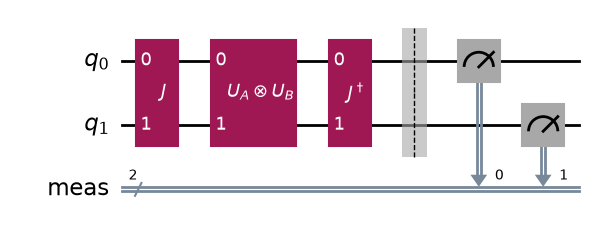


Measuremnt results:
counts:{'11': 262, '01': 244, '00': 266, '10': 252}
probabilities: [0.26 0.24 0.25 0.26]

Alice Playoff: 2.265625
Bob Payoff: 2.2265625


In [89]:
main_qiskit()

In [90]:
strategy_library = QuantumStrategyLibrary.default()

print("Available strategies:")

for i, strategy in enumerate(strategy_library.strategies):
    print(f"{i}: {strategy.name}")


quantum_game = CachedQuantumGame(gamma=np.pi/2,shots=1024)


payoff_a,payoff_b = (quantum_game.payoff_matrix(strategy_library))


print("\nAlice payoff matrix:")
print(payoff_a)


print("\n Bob payoff matrix:")
print(payoff_b)


learner = QuantumMixedStrategyLearner(
    strategy_library=strategy_library,
    game=quantum_game,
    n_players=2,
    T0=4.0,
    Tf=0.125,
    tau=30_000,
    epsilon=0.1,
    iterations=400_000,
    seed=42)

learner.run()





Available strategies:
0: C
1: D
2: Q
3: M
4: A

Alice payoff matrix:
[[3.   0.   1.   1.5  1.05]
 [5.   1.   0.   3.01 0.23]
 [1.   5.   3.   3.03 3.07]
 [4.02 0.5  0.53 2.3  0.31]
 [1.4  4.53 2.73 4.1  2.73]]

 Bob payoff matrix:
[[3.   5.   1.   4.   1.36]
 [0.   1.   5.   0.5  4.44]
 [1.   0.   3.   0.49 2.79]
 [1.47 2.98 2.9  2.15 4.15]
 [1.08 0.19 3.12 0.36 2.81]]


In [91]:
learner.print_summary()
mav = learner.iterations // 20


LEARNING RESULTS
Iterations       : 400000
Initial T        : 4.0
Final T          : 0.125006
Epsilon          : 0.1

Final Q-tables:

Player 1
    C : Q =   1.1030, count = 13650
    D : Q =   0.7095, count = 14222
    Q : Q =   3.0194, count = 266459
    M : Q =   0.8367, count = 13682
    A : Q =   2.8092, count = 91986

Player 2
    C : Q =   1.1072, count = 13402
    D : Q =   0.7191, count = 14211
    Q : Q =   3.0257, count = 252778
    M : Q =   0.8360, count = 13736
    A : Q =   2.8569, count = 105872

Final Boltzmann mixed strategies:

Player 1
  P(C) = 0.000000
  P(D) = 0.000000
  P(Q) = 0.843171
  P(M) = 0.000000
  P(A) = 0.156829

Player 2
  P(C) = 0.000000
  P(D) = 0.000000
  P(Q) = 0.794112
  P(M) = 0.000000
  P(A) = 0.205888

Empirical frequencies over last 10%:

Player 1
    C : 0.020950
    D : 0.020125
    Q : 0.775900
    M : 0.020550
    A : 0.162475

Player 2
    C : 0.019900
    D : 0.020475
    Q : 0.734300
    M : 0.020200
    A : 0.205125


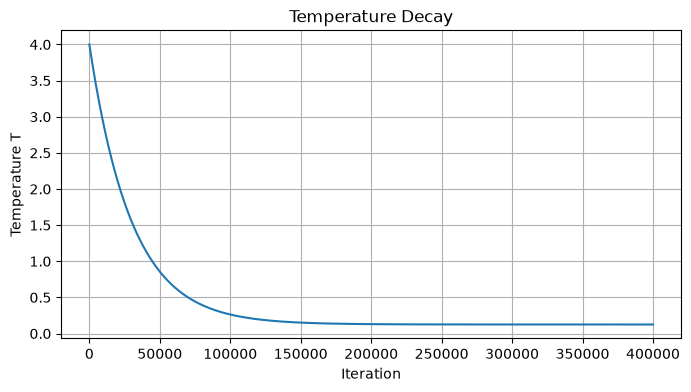

In [92]:
LearnigPlotter.plot_temperature(learner)

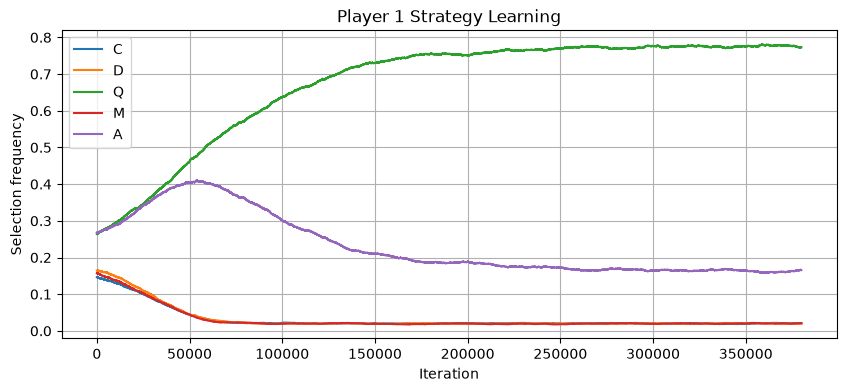

In [93]:
LearnigPlotter.plot_strategy_selection(learner,player=0,moving_average_window=mav)



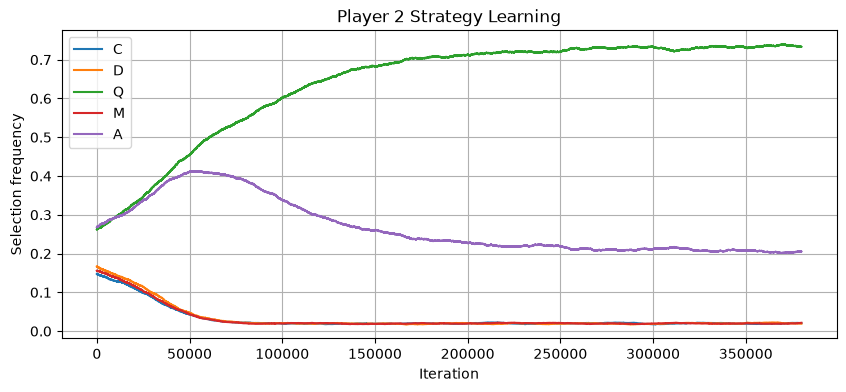

In [94]:
LearnigPlotter.plot_strategy_selection(learner,player=1,moving_average_window=mav)

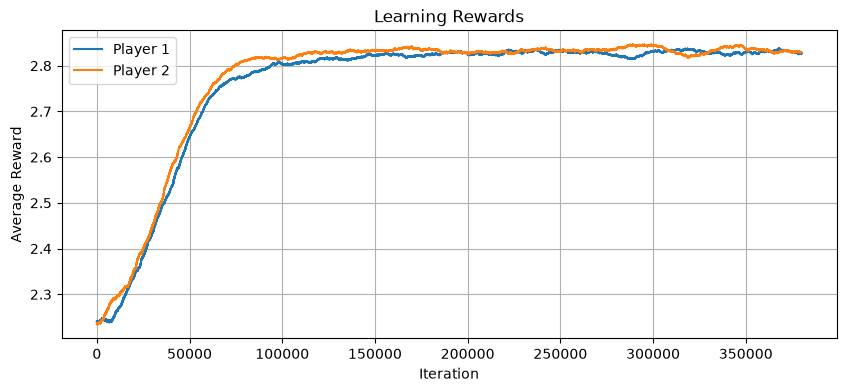

In [95]:
LearnigPlotter.plot_reward(learner,moving_average_window=mav)